# TABLA FECHA PUBLICACION

In [ ]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import plotly.express as px

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


In [ ]:
df = pd.read_json(DATA_RAW / "fecha.json")
df


,blues.00000.wav,blues.00001.wav,blues.00002.wav,blues.00003.wav,blues.00004.wav,blues.00005.wav,blues.00006.wav,blues.00007.wav,blues.00008.wav,blues.00009.wav,...,rock.00090.wav,rock.00091.wav,rock.00092.wav,rock.00093.wav,rock.00094.wav,rock.00095.wav,rock.00096.wav,rock.00097.wav,rock.00098.wav,rock.00099.wav
dia,17,31,14,29,22.0,11,20,13,20,13,...,4,32,4,20,31.0,20,24,11,27,13
mes,10,7,6,5,6.0,5,8,5,5,1,...,11,11,3,2,12.0,10,9,8,2,10
year,1,2023,2023,2023,NaN,2023,2021,1,2021,2023,...,2021,2021,2023,2021,NaN,2022,2021,2022,2022,2022


# Tratamiento de los datos JSON

In [ ]:
df_fecha = df.transpose().reset_index()
df_fecha

df_fecha.columns = ['cancion', 'dia', 'mes', 'año']
df_fecha = df_fecha.astype({'dia':'Int64', 'mes':'Int64', 'año':'Int64'})
df_fecha

,cancion,dia,mes,año
0,blues.00000.wav,17,10,1
1,blues.00001.wav,31,7,2023
2,blues.00002.wav,14,6,2023
3,blues.00003.wav,29,5,2023
4,blues.00004.wav,22,6,<NA>
...,...,...,...,...
995,rock.00095.wav,20,10,2022
996,rock.00096.wav,24,9,2021
997,rock.00097.wav,11,8,2022
998,rock.00098.wav,27,2,2022


In [ ]:
#Dado que tenemos las columnas día, mes y año, vamos a contruir una fecha completa
df_fecha['fecha_publicacion'] = df_fecha['año'].astype(str).str.zfill(4) + "-" + df_fecha['mes'].astype(str).str.zfill(2) + "-" + df_fecha['dia'].astype(str).str.zfill(2)
df_fecha

,cancion,dia,mes,año,fecha_publicacion
0,blues.00000.wav,17,10,1,0001-10-17
1,blues.00001.wav,31,7,2023,2023-07-31
2,blues.00002.wav,14,6,2023,2023-06-14
3,blues.00003.wav,29,5,2023,2023-05-29
4,blues.00004.wav,22,6,<NA>,<NA>-06-22
...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20
996,rock.00096.wav,24,9,2021,2021-09-24
997,rock.00097.wav,11,8,2022,2022-08-11
998,rock.00098.wav,27,2,2022,2022-02-27


In [ ]:
#pasamos a nulos las fechas que estan mal configuradas
df_fecha['fecha_publicacion'] = pd.to_datetime(df_fecha['fecha_publicacion'], errors='coerce')
df_fecha.head(11)

/tmp/ipykernel_484/2321892646.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_fecha['fecha_publicacion'] = pd.to_datetime(df_fecha['fecha_publicacion'], errors='coerce')


,cancion,dia,mes,año,fecha_publicacion
0,blues.00000.wav,17,10,1,NaT
1,blues.00001.wav,31,7,2023,2023-07-31
2,blues.00002.wav,14,6,2023,2023-06-14
3,blues.00003.wav,29,5,2023,2023-05-29
4,blues.00004.wav,22,6,<NA>,NaT
5,blues.00005.wav,11,5,2023,2023-05-11
6,blues.00006.wav,20,8,2021,2021-08-20
7,blues.00007.wav,13,5,1,NaT
8,blues.00008.wav,20,5,2021,2021-05-20
9,blues.00009.wav,13,1,2023,2023-01-13


# Primer analisis general de los datos

In [ ]:
#Comprobamos el tipo de dato y si exiten nulos
df_fecha.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cancion            1000 non-null   object        
 1   dia                994 non-null    Int64         
 2   mes                991 non-null    Int64         
 3   año                983 non-null    Int64         
 4   fecha_publicacion  835 non-null    datetime64[ns]
dtypes: Int64(3), datetime64[ns](1), object(1)
memory usage: 42.1+ KB


In [ ]:
df_fecha.head(5)

,cancion,dia,mes,año,fecha_publicacion
0,blues.00000.wav,17,10,1,NaT
1,blues.00001.wav,31,7,2023,2023-07-31
2,blues.00002.wav,14,6,2023,2023-06-14
3,blues.00003.wav,29,5,2023,2023-05-29
4,blues.00004.wav,22,6,<NA>,NaT


In [ ]:
df_fecha.tail(5)

,cancion,dia,mes,año,fecha_publicacion
995,rock.00095.wav,20,10,2022,2022-10-20
996,rock.00096.wav,24,9,2021,2021-09-24
997,rock.00097.wav,11,8,2022,2022-08-11
998,rock.00098.wav,27,2,2022,2022-02-27
999,rock.00099.wav,13,10,2022,2022-10-13


In [ ]:
#Vemos cuantas fechas nulas tenemos en nuestra tabla
df_fecha['fecha_publicacion'].isna().value_counts()

,count
fecha_publicacion,
False,835
True,165


In [ ]:
#Buscamos duplicados en la columna canción
df_fecha['cancion'].duplicated().any()

np.False_

In [ ]:
#Identificamos registros con valores de días no válidos
dias_no_existentes = df_fecha[(df_fecha['dia']<1) | (df_fecha['dia'].isna()) | (df_fecha['dia']>31) | ((df_fecha['mes'].isin([4,6,9,11])) & (df_fecha['dia']>30)) | ((df_fecha['mes']==2) & (df_fecha['dia']>29))]
dias_no_existentes

,cancion,dia,mes,año,fecha_publicacion
10,blues.00010.wav,32,8,2021,NaT
46,blues.00046.wav,0,0,2023,NaT
59,blues.00059.wav,34,4,2022,NaT
92,blues.00092.wav,0,0,2023,NaT
98,blues.00098.wav,34,8,2023,NaT
...,...,...,...,...,...
939,rock.00039.wav,0,11,2021,NaT
944,rock.00044.wav,<NA>,<NA>,2023,NaT
960,rock.00060.wav,0,9,2021,NaT
984,rock.00084.wav,0,11,2022,NaT


In [ ]:
#Identificamos registros con valores de meses no válidos
meses_no_existentes = df_fecha[(df_fecha['mes']<1) | (df_fecha['mes'].isna()) |(df_fecha['mes']>12)]
meses_no_existentes

,cancion,dia,mes,año,fecha_publicacion
46,blues.00046.wav,0,0,2023,NaT
92,blues.00092.wav,0,0,2023,NaT
105,classical.00005.wav,0,<NA>,2022,NaT
191,classical.00091.wav,<NA>,<NA>,2021,NaT
586,jazz.00086.wav,0,<NA>,1,NaT
631,metal.00031.wav,<NA>,<NA>,2023,NaT
647,metal.00047.wav,0,0,2023,NaT
677,metal.00077.wav,0,0,2021,NaT
723,pop.00023.wav,0,0,2023,NaT
763,pop.00063.wav,<NA>,0,2023,NaT


In [ ]:
#Identificamos registros con valores de años no válidos
años_no_existentes = df_fecha[(df_fecha['año']<1900) | (df_fecha['año'].isna()) | (df_fecha['año']>2026)]
años_no_existentes

,cancion,dia,mes,año,fecha_publicacion
0,blues.00000.wav,17,10,1,NaT
4,blues.00004.wav,22,6,<NA>,NaT
7,blues.00007.wav,13,5,1,NaT
20,blues.00020.wav,6,4,<NA>,NaT
22,blues.00022.wav,2,2,1,NaT
...,...,...,...,...,...
949,rock.00049.wav,1,3,0,NaT
950,rock.00050.wav,13,11,-7,NaT
965,rock.00065.wav,11,3,0,NaT
968,rock.00068.wav,6,6,<NA>,NaT


In [ ]:
#creamos un dataframe con todas las fechas erroneas para su posterior estudio
df_fechas_erroneas = df_fecha[(df_fecha['dia']<1) | (df_fecha['dia'].isna()) | (df_fecha['dia']>31) | ((df_fecha['mes'].isin([4,6,9,11])) & (df_fecha['dia']>30)) | ((df_fecha['mes']==2) & (df_fecha['dia']>29))
| (df_fecha['mes']<1) | (df_fecha['mes'].isna()) |(df_fecha['mes']>12)
| (df_fecha['año']<1900) | (df_fecha['año'].isna()) | (df_fecha['año']>2026)]
display(df_fechas_erroneas)

print(f'Total fechas erroneas: {len(df_fechas_erroneas)}')
print(f'Porcentaje de fechas erroneas {len(df_fechas_erroneas)/len(df_fecha)*100}%')


,cancion,dia,mes,año,fecha_publicacion
0,blues.00000.wav,17,10,1,NaT
4,blues.00004.wav,22,6,<NA>,NaT
7,blues.00007.wav,13,5,1,NaT
10,blues.00010.wav,32,8,2021,NaT
20,blues.00020.wav,6,4,<NA>,NaT
...,...,...,...,...,...
965,rock.00065.wav,11,3,0,NaT
968,rock.00068.wav,6,6,<NA>,NaT
984,rock.00084.wav,0,11,2022,NaT
991,rock.00091.wav,32,11,2021,NaT


Total fechas erroneas: 165
Porcentaje de fechas erroneas 16.5%


In [ ]:
#Vemos si el numero total de fechas mal coinciden con las que pusimos a null en el tratamiento de datos JSON
len(df_fecha[df_fecha['fecha_publicacion'].isna()])==len(df_fechas_erroneas)

True

#Construcción de tabla para sql

In [ ]:
# Para optimizar el rendimiento de la tabla en sql, vamos a utilizar el campo id_cancion construido en la tabla canción
df_cancion = pd.read_csv(DATA_PROCESSED / "cancion.csv")
df_fecha1 = pd.merge(df_fecha, df_cancion, on='cancion', how='left')
df_fecha1.head(11)


,cancion,dia,mes,año,fecha_publicacion,id_cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,blues.00000.wav,17,10,1,NaT,1,00:02:18,744.01,1,1,1,1
1,blues.00001.wav,31,7,2023,2023-07-31,2,00:02:22,4178.85,1,2,2,2
2,blues.00002.wav,14,6,2023,2023-06-14,3,00:01:36,3226.40,1,3,4,3
3,blues.00003.wav,29,5,2023,2023-05-29,4,00:01:51,3618.77,1,4,6,4
4,blues.00004.wav,22,6,<NA>,NaT,5,00:03:11,1990.81,1,5,7,5
5,blues.00005.wav,11,5,2023,2023-05-11,6,00:03:51,909.81,1,6,9,6
6,blues.00006.wav,20,8,2021,2021-08-20,7,00:02:40,2311.44,1,6,11,7
7,blues.00007.wav,13,5,1,NaT,8,00:03:06,2794.92,1,2,13,8
8,blues.00008.wav,20,5,2021,2021-05-20,9,NaN,2844.92,1,2,14,9
9,blues.00009.wav,13,1,2023,2023-01-13,10,00:04:03,3760.17,1,6,7,10


In [ ]:
df_fecha_final = df_fecha1[['id_cancion', 'fecha_publicacion']]
df_fecha_final

,id_cancion,fecha_publicacion
0,1,NaT
1,2,2023-07-31
2,3,2023-06-14
3,4,2023-05-29
4,5,NaT
...,...,...
995,996,2022-10-20
996,997,2021-09-24
997,998,2022-08-11
998,999,2022-02-27


In [ ]:
df_fecha_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id_cancion         1000 non-null   int64         
 1   fecha_publicacion  835 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(1)
memory usage: 15.8 KB


In [ ]:
df_fecha_final.to_csv(DATA_PROCESSED / "fecha_publicacion.csv", index=False)


#Tratamiento de errores

¿Que hacemos con las fechas errorenas?

In [ ]:
#Recuperamos la cantidad de fechas errorenas
print(f'Total fechas erroneas: {len(df_fechas_erroneas)}')
print(f'Porcentaje de fechas erroneas {len(df_fechas_erroneas)/len(df_fecha)*100}%')

Total fechas erroneas: 165
Porcentaje de fechas erroneas 16.5%


In [ ]:
#Porcentaje de fechas erroneas por género
df_fechas_erroneas = df_fechas_erroneas.copy()

df_fechas_erroneas['genero'] = df_fechas_erroneas['cancion'].apply(lambda x: x.split('.')[0])
df_fecha['genero'] = df_fecha['cancion'].apply(lambda x: x.split('.')[0])

errores_genero = df_fechas_erroneas['genero'].value_counts()
total_genero = df_fecha['genero'].value_counts()

porcentaje_errores = (errores_genero / total_genero * 100).round(2).astype(str) + '%'
porcentaje_errores = porcentaje_errores.rename('porcentaje_errores').to_frame().reset_index()
porcentaje_errores

,genero,porcentaje_errores
0,blues,14.0%
1,classical,22.0%
2,country,13.0%
3,disco,17.0%
4,hiphop,11.0%
5,jazz,21.0%
6,metal,19.0%
7,pop,15.0%
8,reggae,16.0%
9,rock,17.0%


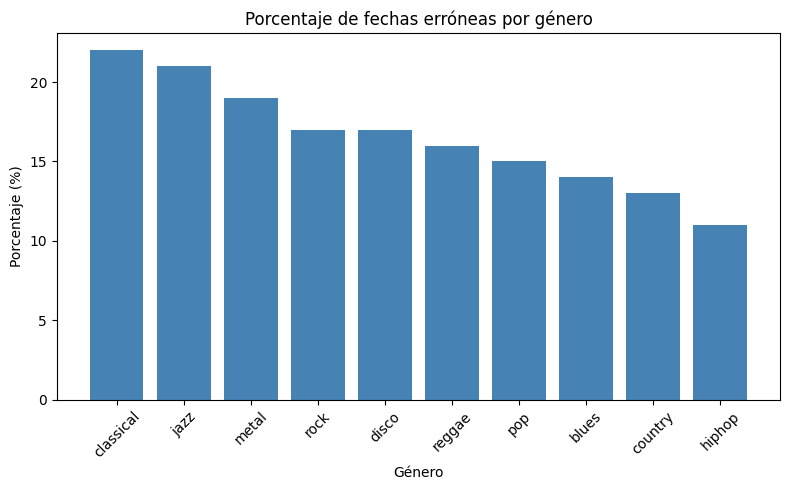

In [ ]:
porcentaje_errores_num = (errores_genero / total_genero * 100).round(2).rename('porcentaje_errores').to_frame().reset_index().sort_values(by='porcentaje_errores',ascending=False)

plt.figure(figsize=(8,5))
ax = plt.bar(
    porcentaje_errores_num['genero'],
    porcentaje_errores_num['porcentaje_errores'],
    color='steelblue'
)


plt.title('Porcentaje de fechas erróneas por género')
plt.xlabel('Género')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=45)


plt.tight_layout()
plt.show()

Los errores se distribuyen de forma similar entre los distintos géneros. El porcentaje de registros afectados en cada género oscila entre el 11 % y el 22 %, por lo que no se aprecia una concentración extrema que justifique un tratamiento diferenciado según el género musical

Analicemos la distribución de cada columna sin las fechas erroneas para ver que tipo de normalización aplicamos

In [ ]:
df_fecha_dia = df_fecha[df_fecha['cancion'].isin(dias_no_existentes['cancion']) == False]
df_fecha_dia

,cancion,dia,mes,año,fecha_publicacion,genero
0,blues.00000.wav,17,10,1,NaT,blues
1,blues.00001.wav,31,7,2023,2023-07-31,blues
2,blues.00002.wav,14,6,2023,2023-06-14,blues
3,blues.00003.wav,29,5,2023,2023-05-29,blues
4,blues.00004.wav,22,6,<NA>,NaT,blues
...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock
996,rock.00096.wav,24,9,2021,2021-09-24,rock
997,rock.00097.wav,11,8,2022,2022-08-11,rock
998,rock.00098.wav,27,2,2022,2022-02-27,rock


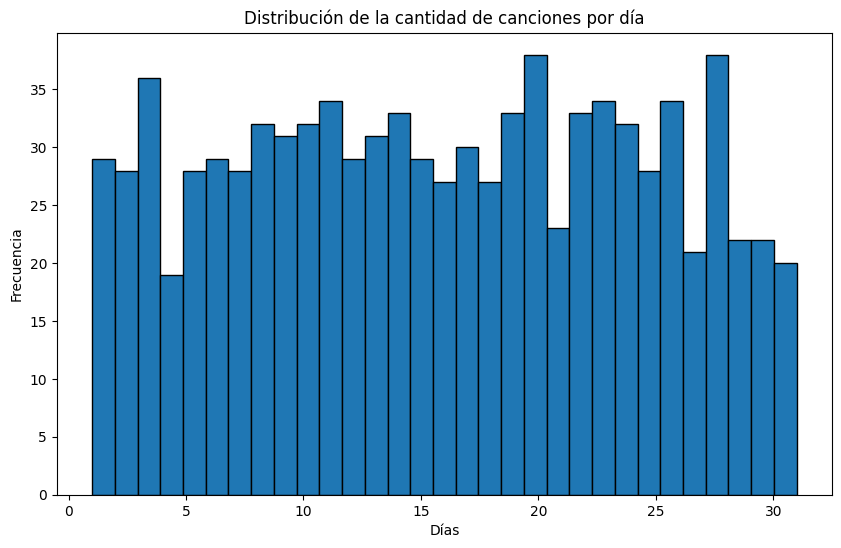

In [ ]:
#Histograma
plt.figure(figsize=(10, 6))
plt.hist(df_fecha_dia['dia'], bins=31, edgecolor='black')
plt.xlabel('Días')
plt.ylabel('Frecuencia')
plt.title('Distribución de la cantidad de canciones por día')
plt.show()

In [ ]:
dias_no_existentes['dia'].value_counts(dropna=False)

,count
dia,
0,36
34,11
33,11
32,9
36,7
35,7
<NA>,6
31,3


La distribución de los valores válidos de la variable día es relativamente homogénea, sin concentraciones significativas que indiquen una mayor frecuencia en determinados días del mes. Por otro lado, los valores no válidos se concentran en los días 0 y en los compredidos entre 32 y 36, además de algunos valores nulos.

In [ ]:
df_fecha_mes = df_fecha[df_fecha['cancion'].isin(meses_no_existentes['cancion']) == False]
df_fecha_mes

,cancion,dia,mes,año,fecha_publicacion,genero
0,blues.00000.wav,17,10,1,NaT,blues
1,blues.00001.wav,31,7,2023,2023-07-31,blues
2,blues.00002.wav,14,6,2023,2023-06-14,blues
3,blues.00003.wav,29,5,2023,2023-05-29,blues
4,blues.00004.wav,22,6,<NA>,NaT,blues
...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock
996,rock.00096.wav,24,9,2021,2021-09-24,rock
997,rock.00097.wav,11,8,2022,2022-08-11,rock
998,rock.00098.wav,27,2,2022,2022-02-27,rock


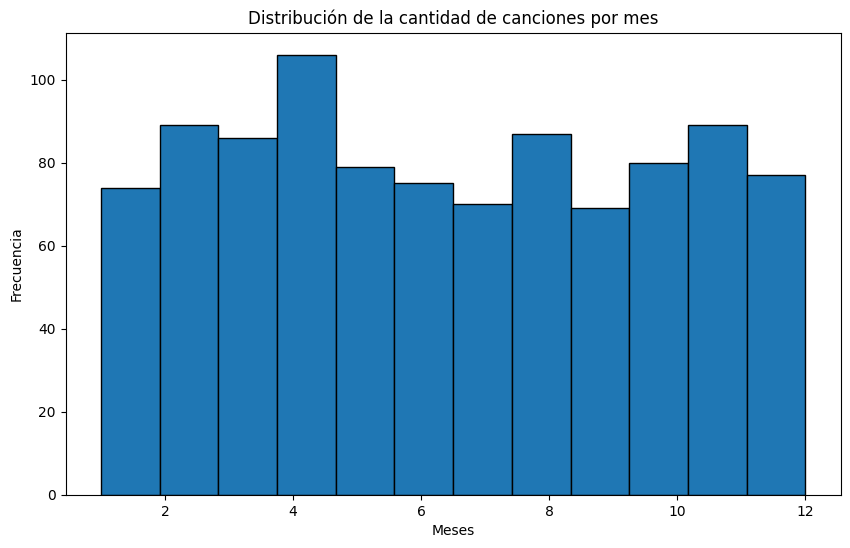

In [ ]:
#Histograma
plt.figure(figsize=(10, 6))
plt.hist(df_fecha_mes['mes'], bins=12, edgecolor='black')
plt.xlabel('Meses')
plt.ylabel('Frecuencia')
plt.title('Distribución de la cantidad de canciones por mes')
plt.show()

In [ ]:
meses_no_existentes['mes'].value_counts(dropna=False)

,count
mes,
0,10
<NA>,9


La distribución de los meses no presenta desequilibrios significativos, observándose registros en todos los meses del año. Los errores identificados corresponden exclusivamente a valores nulos y meses iguales a 0, sin detectarse valores superiores a 12

In [ ]:
df_fecha_año = df_fecha[df_fecha['cancion'].isin(años_no_existentes['cancion']) == False]
df_fecha_año

,cancion,dia,mes,año,fecha_publicacion,genero
1,blues.00001.wav,31,7,2023,2023-07-31,blues
2,blues.00002.wav,14,6,2023,2023-06-14,blues
3,blues.00003.wav,29,5,2023,2023-05-29,blues
5,blues.00005.wav,11,5,2023,2023-05-11,blues
6,blues.00006.wav,20,8,2021,2021-08-20,blues
...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock
996,rock.00096.wav,24,9,2021,2021-09-24,rock
997,rock.00097.wav,11,8,2022,2022-08-11,rock
998,rock.00098.wav,27,2,2022,2022-02-27,rock


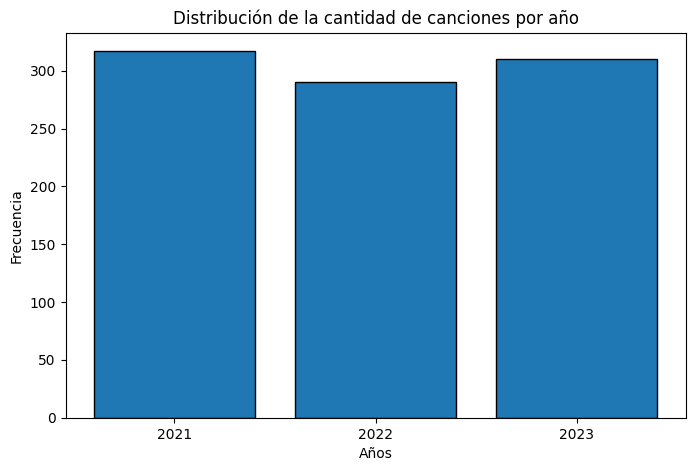

In [ ]:
#Histograma
conteo = df_fecha_año['año'].value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.bar(conteo.index.astype(int), conteo.values, edgecolor='black')
plt.xlabel('Años')
plt.ylabel('Frecuencia')
plt.title('Distribución de la cantidad de canciones por año')
plt.xticks(conteo.index.astype(int))
plt.show()

In [ ]:
años_no_existentes['año'].value_counts(dropna=False)

,count
año,
-7,19
0,19
<NA>,17
2,15
1,13


El análisis de la variable año muestra la presencia de valores nulos y años claramente inválidos, como -7, 0, 1 y 2. Estos valores no presentan un patrón que permita inferir de forma fiable el año correcto. Por lo tanto, los registros con años inválidos serán excluidos del análisis posterior

In [ ]:
#Cuantos errores hay por fecha
mask_dia = ((df_fecha['dia'] < 1) | (df_fecha['dia'].isna()) | (df_fecha['dia'] > 31))

mask_mes = ((df_fecha['mes'] < 1) | (df_fecha['mes'].isna()) | (df_fecha['mes'] > 12))

mask_año = ((df_fecha['año'] < 1900) | (df_fecha['año'].isna()) | (df_fecha['año'] > 2026))


errores_por_fila = (mask_dia.astype(int) + mask_mes.astype(int) + mask_año.astype(int))

errores_por_fila.value_counts().sort_index()

,count
0,838
1,136
2,25
3,1


El análisis del número de errores por registro muestra que la mayoría de las fechas inválidas presentan un único componente incorrecto. No obstante, se identificaron 25 registros con dos errores simultáneos y un registro con errores en día, mes y año

**Conclusión:** Como estrategia de tratamiento, se establece que los registros con valores nulos, aquellos que presentan dos o más componentes de la fecha erróneos y los que contienen valores imposibles de reconstruir de forma fiable serán eliminados del conjunto de datos. Por otro lado, los registros cuyo único problema sea un valor del día superior al máximo permitido (32–36), manteniendo el mes y el año válidos, serán corregidos mediante un desplazamiento temporal al mes siguiente, permitiendo obtener una fecha válida sin perder información.

#Limpieza de datos

In [ ]:
#En primer lugar, se eliminan los registros con valores nulos en alguno de los tres componentes de la fecha debido a que no se pueden reconstruir dichas fechas
df_fecha_sin_nulos = df_fecha[df_fecha['dia'].notna() & df_fecha['mes'].notna() & df_fecha['año'].notna()]
df_fecha_sin_nulos

,cancion,dia,mes,año,fecha_publicacion,genero
0,blues.00000.wav,17,10,1,NaT,blues
1,blues.00001.wav,31,7,2023,2023-07-31,blues
2,blues.00002.wav,14,6,2023,2023-06-14,blues
3,blues.00003.wav,29,5,2023,2023-05-29,blues
5,blues.00005.wav,11,5,2023,2023-05-11,blues
...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock
996,rock.00096.wav,24,9,2021,2021-09-24,rock
997,rock.00097.wav,11,8,2022,2022-08-11,rock
998,rock.00098.wav,27,2,2022,2022-02-27,rock


In [ ]:
#Registros que tienen 2 o mas valores mal
df_dos_errores = df_fecha_sin_nulos[errores_por_fila>1]
df_dos_errores

/tmp/ipykernel_484/2424825652.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_dos_errores = df_fecha_sin_nulos[errores_por_fila>1]


,cancion,dia,mes,año,fecha_publicacion,genero
46,blues.00046.wav,0,0,2023,NaT,blues
92,blues.00092.wav,0,0,2023,NaT,blues
110,classical.00010.wav,0,10,2,NaT,classical
358,disco.00058.wav,33,9,2,NaT,disco
465,hiphop.00065.wav,33,7,-7,NaT,hiphop
495,hiphop.00095.wav,36,5,2,NaT,hiphop
532,jazz.00032.wav,34,12,-7,NaT,jazz
585,jazz.00085.wav,33,12,0,NaT,jazz
647,metal.00047.wav,0,0,2023,NaT,metal
677,metal.00077.wav,0,0,2021,NaT,metal


In [ ]:
#Eliminamos los registros que tienen 2 o más valores mal debido a que no se puede reconstruir una fecha fiable
df_fecha_sin_errores = df_fecha_sin_nulos[errores_por_fila<=1]
df_fecha_sin_errores

/tmp/ipykernel_484/3734770054.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_fecha_sin_errores = df_fecha_sin_nulos[errores_por_fila<=1]


,cancion,dia,mes,año,fecha_publicacion,genero
0,blues.00000.wav,17,10,1,NaT,blues
1,blues.00001.wav,31,7,2023,2023-07-31,blues
2,blues.00002.wav,14,6,2023,2023-06-14,blues
3,blues.00003.wav,29,5,2023,2023-05-29,blues
5,blues.00005.wav,11,5,2023,2023-05-11,blues
...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock
996,rock.00096.wav,24,9,2021,2021-09-24,rock
997,rock.00097.wav,11,8,2022,2022-08-11,rock
998,rock.00098.wav,27,2,2022,2022-02-27,rock


Se corrigen los registros con días entre 32 y 36 mediante un desplazamiento temporal al mes siguiente y los registros con valor 0 se eliminan, ya que este valor no admite una interpretación única que permita reconstruir la fecha original con suficiente fiabilidad.

In [ ]:
#Elimina los registros con día 0
df_fecha_sin_errores = df_fecha_sin_errores[df_fecha_sin_errores['dia'] != 0]

In [ ]:
#Conversión de fechas
df_fecha_sin_errores['fecha_base'] = pd.to_datetime(
    dict(
        year=df_fecha_sin_errores['año'],
        month=df_fecha_sin_errores['mes'],
        day=1
    ),
    errors='coerce'
)

df_fecha_sin_errores['fecha_normalizada'] = df_fecha_sin_errores['fecha_base'] + + pd.to_timedelta(df_fecha_sin_errores['dia'] - 1, unit='D')

/tmp/ipykernel_484/3876064342.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fecha_sin_errores['fecha_base'] = pd.to_datetime(
/tmp/ipykernel_484/3876064342.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fecha_sin_errores['fecha_normalizada'] = df_fecha_sin_errores['fecha_base'] + + pd.to_timedelta(df_fecha_sin_errores['dia'] - 1, unit='D')


In [ ]:
df_fecha_sin_errores

,cancion,dia,mes,año,fecha_publicacion,genero,fecha_base,fecha_normalizada
0,blues.00000.wav,17,10,1,NaT,blues,NaT,NaT
1,blues.00001.wav,31,7,2023,2023-07-31,blues,2023-07-01,2023-07-31
2,blues.00002.wav,14,6,2023,2023-06-14,blues,2023-06-01,2023-06-14
3,blues.00003.wav,29,5,2023,2023-05-29,blues,2023-05-01,2023-05-29
5,blues.00005.wav,11,5,2023,2023-05-11,blues,2023-05-01,2023-05-11
...,...,...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock,2022-10-01,2022-10-20
996,rock.00096.wav,24,9,2021,2021-09-24,rock,2021-09-01,2021-09-24
997,rock.00097.wav,11,8,2022,2022-08-11,rock,2022-08-01,2022-08-11
998,rock.00098.wav,27,2,2022,2022-02-27,rock,2022-02-01,2022-02-27


Los meses inválidos corresponden únicamente a valores nulos o iguales a 0. Al no existir evidencia suficiente para determinar el mes correcto, estos registros serán tratados como valores faltantes.

In [ ]:
#Veamos que valores quedan erroneos en el mes
df_fecha_sin_errores[df_fecha_sin_errores['mes'] == 0]

,cancion,dia,mes,año,fecha_publicacion,genero,fecha_base,fecha_normalizada


Al principio de la limpieza se eliminaron los registros que presentaban valores nulos o más de un componente erróneo en la fecha, al considerarse irrecuperables. Como consecuencia de este proceso, también fueron eliminados todos los registros con mes igual a 0, ya que estos coincidían con alguno de los criterios anteriores y no fue necesario aplicar un tratamiento adicional sobre la variable mes.

In [ ]:
#Veamos que valores quedan erroneos en el año
df_fecha_sin_errores[df_fecha_sin_errores['año'] < 1900]

,cancion,dia,mes,año,fecha_publicacion,genero,fecha_base,fecha_normalizada
0,blues.00000.wav,17,10,1,NaT,blues,NaT,NaT
7,blues.00007.wav,13,5,1,NaT,blues,NaT,NaT
22,blues.00022.wav,2,2,1,NaT,blues,NaT,NaT
45,blues.00045.wav,10,12,2,NaT,blues,NaT,NaT
55,blues.00055.wav,26,2,-7,NaT,blues,NaT,NaT
72,blues.00072.wav,24,6,0,NaT,blues,NaT,NaT
117,classical.00017.wav,8,9,0,NaT,classical,NaT,NaT
154,classical.00054.wav,6,8,-7,NaT,classical,NaT,NaT
164,classical.00064.wav,29,12,-7,NaT,classical,NaT,NaT
167,classical.00067.wav,24,3,2,NaT,classical,NaT,NaT


Respecto a la variable año, se detectaron registros con valores -7, 0, 1 y 2.  Dado que estos valores no se corresponden con el periodo temporal del conjunto de datos y no es posible determinar el año correcto de forma objetiva, se optará por eliminar dichos registros, garantizando así la consistencia del conjunto de datos.

In [ ]:
df_fecha_sin_errores = df_fecha_sin_errores[df_fecha_sin_errores['año'] >= 1900]
df_fecha_sin_errores

,cancion,dia,mes,año,fecha_publicacion,genero,fecha_base,fecha_normalizada
1,blues.00001.wav,31,7,2023,2023-07-31,blues,2023-07-01,2023-07-31
2,blues.00002.wav,14,6,2023,2023-06-14,blues,2023-06-01,2023-06-14
3,blues.00003.wav,29,5,2023,2023-05-29,blues,2023-05-01,2023-05-29
5,blues.00005.wav,11,5,2023,2023-05-11,blues,2023-05-01,2023-05-11
6,blues.00006.wav,20,8,2021,2021-08-20,blues,2021-08-01,2021-08-20
...,...,...,...,...,...,...,...,...
995,rock.00095.wav,20,10,2022,2022-10-20,rock,2022-10-01,2022-10-20
996,rock.00096.wav,24,9,2021,2021-09-24,rock,2021-09-01,2021-09-24
997,rock.00097.wav,11,8,2022,2022-08-11,rock,2022-08-01,2022-08-11
998,rock.00098.wav,27,2,2022,2022-02-27,rock,2022-02-01,2022-02-27


In [ ]:
#vemos los valores corregidos
df_fecha_sin_errores[(df_fecha_sin_errores["fecha_normalizada"].notna()) & (df_fecha_sin_errores["fecha_publicacion"].isna())]

,cancion,dia,mes,año,fecha_publicacion,genero,fecha_base,fecha_normalizada
10,blues.00010.wav,32,8,2021,NaT,blues,2021-08-01,2021-09-01
59,blues.00059.wav,34,4,2022,NaT,blues,2022-04-01,2022-05-04
98,blues.00098.wav,34,8,2023,NaT,blues,2023-08-01,2023-09-03
100,classical.00000.wav,33,9,2023,NaT,classical,2023-09-01,2023-10-03
111,classical.00011.wav,33,3,2022,NaT,classical,2022-03-01,2022-04-02
129,classical.00029.wav,34,4,2021,NaT,classical,2021-04-01,2021-05-04
132,classical.00032.wav,31,6,2021,NaT,classical,2021-06-01,2021-07-01
145,classical.00045.wav,34,7,2023,NaT,classical,2023-07-01,2023-08-03
161,classical.00061.wav,33,6,2023,NaT,classical,2023-06-01,2023-07-03
172,classical.00072.wav,32,9,2021,NaT,classical,2021-09-01,2021-10-02


In [ ]:
#valores que aun quedan por normalizar
df_fecha_sin_errores[df_fecha_sin_errores['fecha_normalizada'].isna()]

,cancion,dia,mes,año,fecha_publicacion,genero,fecha_base,fecha_normalizada


In [ ]:
#Quitamos las columnas dia, mes, año debido a que algunas se han cambiado con las limpieza y la fecha correcta esta en la columna fecha_normalizada.
#Ademas, quitamos fecha_publicacion y fecha_base porque no son necesarias
df_fecha_limpio = df_fecha_sin_errores[['cancion','fecha_normalizada','genero']]
df_fecha_limpio

,cancion,fecha_normalizada,genero
1,blues.00001.wav,2023-07-31,blues
2,blues.00002.wav,2023-06-14,blues
3,blues.00003.wav,2023-05-29,blues
5,blues.00005.wav,2023-05-11,blues
6,blues.00006.wav,2021-08-20,blues
...,...,...,...
995,rock.00095.wav,2022-10-20,rock
996,rock.00096.wav,2021-09-24,rock
997,rock.00097.wav,2022-08-11,rock
998,rock.00098.wav,2022-02-27,rock


In [ ]:
df_fecha_limpio.to_csv(DATA_PROCESSED / "fecha_limpio.csv", index=False)


In [ ]:
#Fechas sin poder corregir
print(f'Total fechas erroneas: {1000-len(df_fecha_limpio)}')

Total fechas erroneas: 122


#EDA

Continuaremos el EDA con el df_fecha_limpio

In [ ]:
df_fecha_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 878 entries, 1 to 999
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cancion            878 non-null    object        
 1   fecha_normalizada  878 non-null    datetime64[ns]
 2   genero             878 non-null    object        
dtypes: datetime64[ns](1), object(2)
memory usage: 27.4+ KB


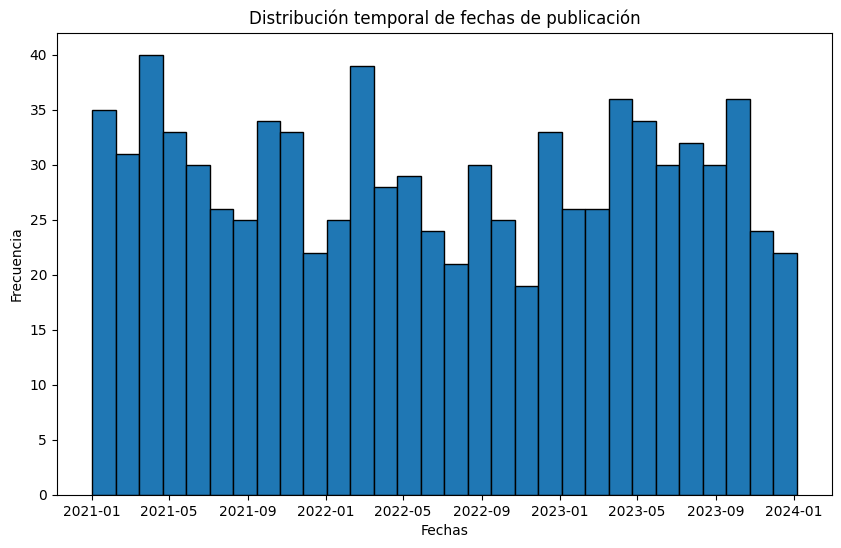

In [ ]:
#Histograma
plt.figure(figsize=(10, 6))
plt.hist(df_fecha_limpio['fecha_normalizada'], bins=30, edgecolor='black')
plt.xlabel('Fechas')
plt.ylabel('Frecuencia')
plt.title('Distribución temporal de fechas de publicación')
plt.show()

In [ ]:
df_fecha_limpio.groupby(df_fecha_limpio['fecha_normalizada'].dt.year).size()

,0
fecha_normalizada,
2021,306
2022,275
2023,295
2024,2


El número de registros por año se mantiene relativamente estable a lo largo del periodo analizado, observándose ligeras variaciones entre años pero sin una tendencia clara de crecimiento o decrecimiento. Además, los pocos registros de 2024 representan casos puntuales y no alteran la distribución temporal del conjunto de datos.

Text(0.5, 0, 'Año')

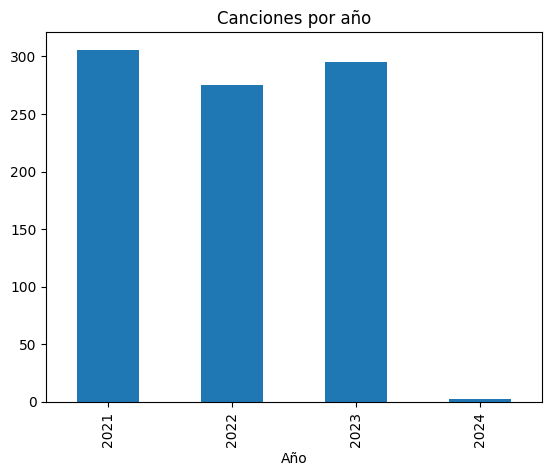

In [ ]:
#vemos el numero de canciones por año
df_fecha_limpio.groupby(df_fecha_limpio['fecha_normalizada'].dt.year).size().plot(kind='bar')
plt.title('Canciones por año')
plt.xlabel('Año')

Text(0.5, 0, 'Mes')

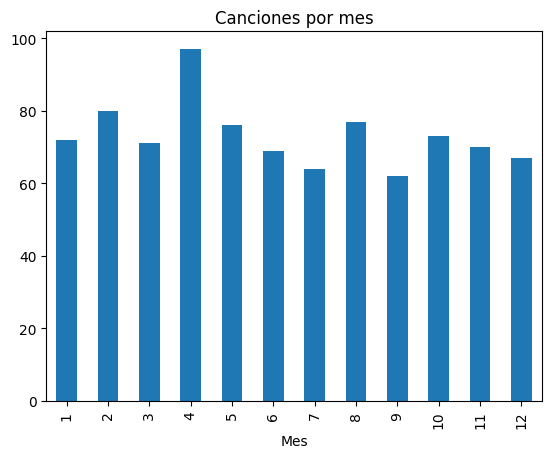

In [ ]:
#vemos el numero de canciones por mes
df_fecha_limpio.groupby(df_fecha_limpio['fecha_normalizada'].dt.month).size().plot(kind='bar')
plt.title('Canciones por mes')
plt.xlabel('Mes')

/tmp/ipykernel_484/1979139059.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_ordenado.set_index('fecha_normalizada').resample('M').size().plot(figsize=(10,5))


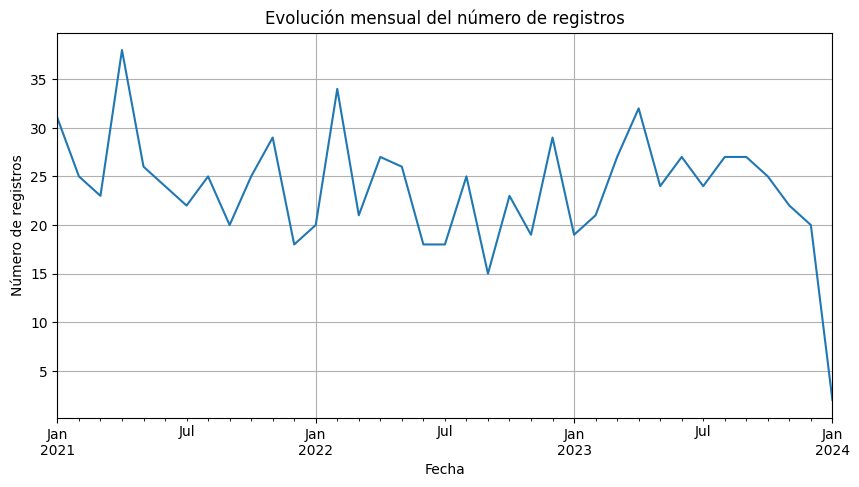

In [ ]:
df_ordenado = df_fecha_limpio.sort_values('fecha_normalizada')

df_ordenado.set_index('fecha_normalizada').resample('M').size().plot(figsize=(10,5))
plt.title('Evolución mensual del número de registros')
plt.xlabel('Fecha')
plt.ylabel('Número de registros')
plt.grid()
plt.show()

In [ ]:
#canciones por año y por genero
df_fecha_limpio['año'] = df_fecha_limpio['fecha_normalizada'].dt.year

df_plot = (df_fecha_limpio.groupby(['año', 'genero']).size().reset_index(name='num_canciones'))

fig2_2 = px.line(df_plot,
             x='año',
             y='num_canciones',
             color='genero',
             title='Evolución de canciones por año y genero',
             template='plotly_white')
fig2_2.update_layout(xaxis_type='category')

fig2_2.show()

#Como ya vimos en 2022 se muestra una disminución de canciones publicadas,
#sin embargo en 2023, este se incrementa has llegar a conseguir el numero mas alto de canciones para algunos generos

/tmp/ipykernel_484/153488424.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fecha_limpio['año'] = df_fecha_limpio['fecha_normalizada'].dt.year


El análisis temporal muestra que las canciones se distribuyen de forma relativamente uniforme entre 2021 y 2023, sin una tendencia clara de crecimiento o descenso. La evolución mensual presenta variaciones normales entre meses, mientras que la distribución por género se mantiene estable a lo largo de los años, sin cambios significativos en el volumen de publicaciones. Los escasos registros de 2024 corresponden únicamente al mes de enero, por lo que no son comparables con los años completos.

In [ ]:
#Vamos a volver a llamar a la tabla cancion para poder hacer mas comparaciones
df_fecha_cancion = pd.merge(df_fecha_limpio,df_cancion,on='cancion',how='left')
df_fecha_cancion.head(11)

,cancion,fecha_normalizada,genero,año,id_cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,blues.00001.wav,2023-07-31,blues,2023,2,00:02:22,4178.85,1,2,2,2
1,blues.00002.wav,2023-06-14,blues,2023,3,00:01:36,3226.40,1,3,4,3
2,blues.00003.wav,2023-05-29,blues,2023,4,00:01:51,3618.77,1,4,6,4
3,blues.00005.wav,2023-05-11,blues,2023,6,00:03:51,909.81,1,6,9,6
4,blues.00006.wav,2021-08-20,blues,2021,7,00:02:40,2311.44,1,6,11,7
5,blues.00008.wav,2021-05-20,blues,2021,9,NaN,2844.92,1,2,14,9
6,blues.00009.wav,2023-01-13,blues,2023,10,00:04:03,3760.17,1,6,7,10
7,blues.00010.wav,2021-09-01,blues,2021,11,00:02:19,469.62,1,7,15,4
8,blues.00011.wav,2021-05-16,blues,2021,12,00:02:07,2218.73,1,8,17,5
9,blues.00012.wav,2023-02-23,blues,2023,13,NaN,2661.39,1,9,5,8


/tmp/ipykernel_484/2623151496.py:1: FutureWarning:

'Y' is deprecated and will be removed in a future version, please use 'YE' instead.



Text(0, 0.5, 'Coste')

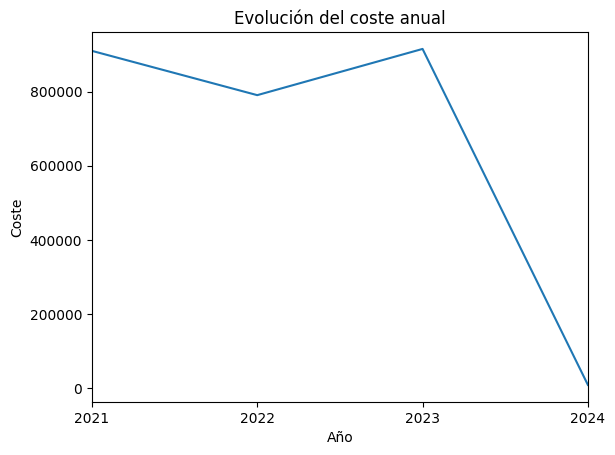

In [ ]:
df_fecha_cancion.set_index('fecha_normalizada').resample('Y')['coste'].sum().plot()
plt.title('Evolución del coste anual')
plt.xlabel('Año')
plt.ylabel('Coste')

El coste anual sigue una evolución similar al número de canciones publicadas. En 2022 se observa un ligero descenso respecto a 2021, mientras que en 2023 el coste aumenta y supera los niveles de los años anteriores. El valor de 2024 no es representativo, ya que únicamente incluye los registros correspondientes al mes de enero.

**Conculsión**

El análisis exploratorio de la variable fecha de publicación permitió evaluar la calidad de los datos temporales y comprobar la fiabilidad para análisis posteriores.
Se comprobó que el conjunto de datos está compuesto por 1.000 canciones y que no existen registros duplicados en la columna identificadora de las canciones, lo que garantiza que cada observación corresponde a una canción única. Durante la validación se identificaron registros con días, meses y años fuera de rango, valores nulos y combinaciones de fecha no válidas, detectándose un total de 165 fechas erróneas, lo que representa aproximadamente el 16,5 % del conjunto de datos.

Este porcentaje indica que una parte relevante de los registros presentan problemas de calidad que deben ser corregidos antes de realizar análisis cronológicos o entrenar modelos que utilicen esta variable como característica predictiva.


El análisis por género mostró que estos errores se distribuyen de forma relativamente uniforme entre las distintas categorías musicales, sin evidencias de un sesgo asociado a un género concreto. Posteriormente, se normalizaron los registros cuya fecha pudo reconstruirse con suficiente fiabilidad y se eliminaron aquellos en los que la información disponible no permitía realizar una corrección fiable.


Tras el proceso de limpieza se obtuvieron 878 canciones con fechas válidas, lo que representa aproximadamente el 87,8 % del conjunto de datos. Este resultado permite trabajar con una variable temporal consistente y fiable.


Finalmente, el análisis temporal muestra que las fechas de publicación se distribuyen de forma equilibrada entre 2021 y 2023, sin concentraciones anómalas. Se observa un ligero descenso en el número de publicaciones durante 2022, seguido de una recuperación en 2023. Los registros correspondientes a 2024 no se consideran representativos, ya que únicamente incluyen publicaciones del mes de enero.